Loading MNIST dataset...
Implementing t-SNE from scratch...
Computing P matrix...
Running optimization...
Iteration 100: KL divergence = 14.9834
Iteration 200: KL divergence = 0.7814
Iteration 300: KL divergence = 0.7400
Iteration 400: KL divergence = 0.7285
Iteration 500: KL divergence = 0.7238
Iteration 600: KL divergence = 0.7213
Iteration 700: KL divergence = 0.7197
Iteration 800: KL divergence = 0.7187
Iteration 900: KL divergence = 0.7179
Iteration 1000: KL divergence = 0.7174


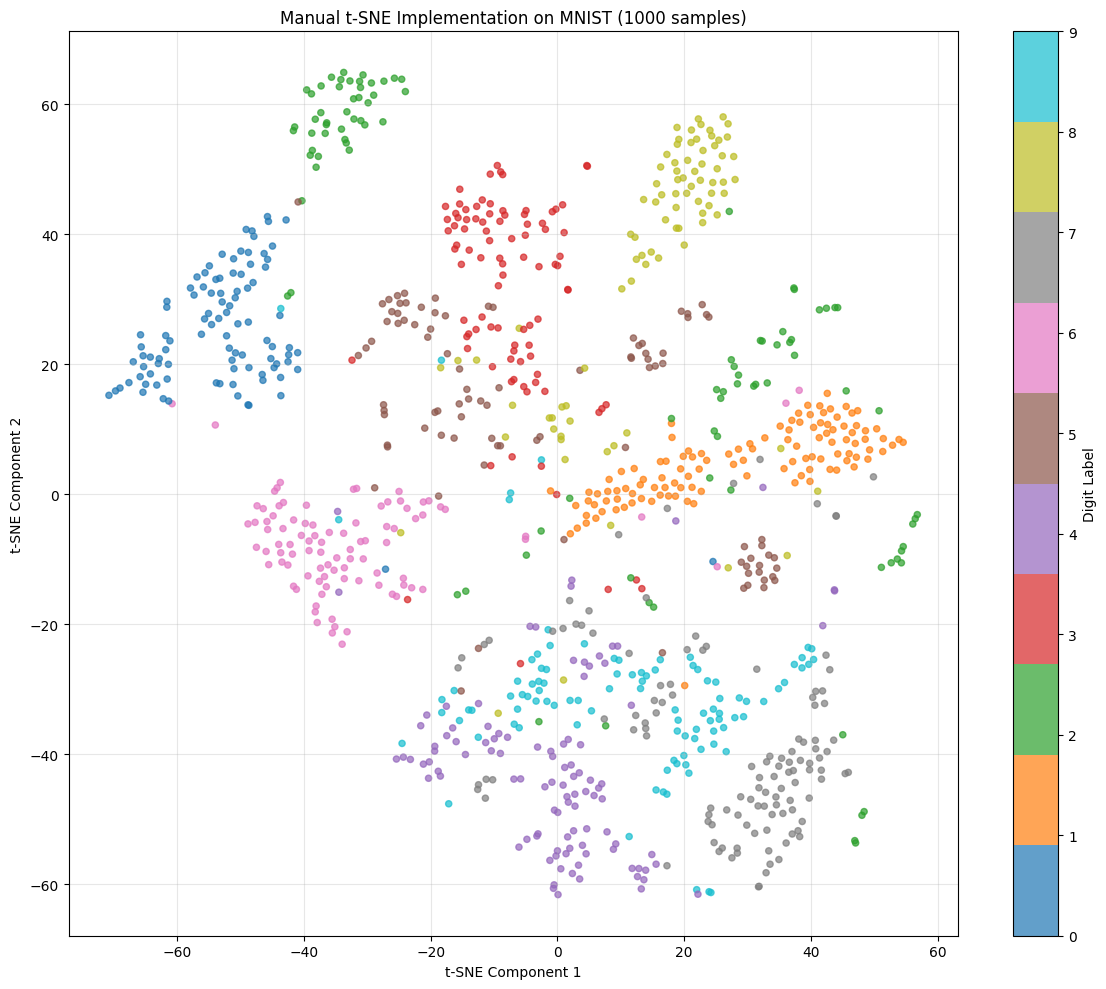

Manual t-SNE visualization complete!


In [2]:
import matplotlib.pyplot as plt          # For plotting and visualization
from sklearn.datasets import fetch_openml  # To load MNIST dataset
import numpy as np                       # For numerical operations

# Load the MNIST dataset
print("Loading MNIST dataset...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
# fetch_openml loads MNIST with 70,000 images of 28x28 pixels (784 features)

X = mnist.data                          # Feature matrix: shape (70000, 784)
                                        # Each row is a flattened 28x28 image
                                        
y = mnist.target.astype(int)            # Labels: convert from string to int (0-9)

# Use a small subset for faster computation
n_samples = 1000                        # Use only 1000 samples (t-SNE is slow)
X_subset = X[:n_samples]                # Take first 1000 images
y_subset = y[:n_samples]                # Take first 1000 labels

# Normalize the data to [0, 1] range
X_subset = X_subset / 255.0             # Pixel values are 0-255, divide by 255

print("Implementing t-SNE from scratch...")

# Step 1: Compute pairwise squared Euclidean distances
def pairwise_distances(X):
    """
    Compute pairwise squared Euclidean distances between all points
    Uses the formula: ||a-b||² = ||a||² + ||b||² - 2*a·b
    """
    sum_X = np.sum(np.square(X), axis=1)  # Compute ||x||² for each row
                                           # Shape: (n_samples,)
    
    # D[i,j] = ||x_i||² + ||x_j||² - 2*x_i·x_j
    D = np.add(np.add(-2 * np.dot(X, X.T), sum_X).T, sum_X)
    # np.dot(X, X.T) computes all dot products: shape (n, n)
    # -2 * dot products, then add row sums and column sums
    # Result: D is an (n, n) matrix of squared distances
    
    return D

# Step 2: Compute P (high-dimensional probabilities)
def compute_p_matrix(X, perplexity=30):
    """
    Compute the P matrix (affinities in high-dimensional space)
    P[i,j] represents the probability that point i picks point j as its neighbor
    """
    n = X.shape[0]                      # Number of samples
    P = np.zeros((n, n))                # Initialize probability matrix
    D = pairwise_distances(X)           # Compute all pairwise distances
    
    # Binary search for sigma that gives desired perplexity
    # Perplexity is a measure of effective number of neighbors
    for i in range(n):                  # For each point i
        beta_min = -np.inf              # Lower bound for beta (precision = 1/2σ²)
        beta_max = np.inf               # Upper bound for beta
        beta = 1.0                      # Initial beta value
        
        # Remove self-distance (don't include point i itself)
        Di = np.concatenate([D[i, :i], D[i, i+1:]])
        # Di contains distances from point i to all other points
        
        for _ in range(50):             # Max 50 iterations for binary search
            # Compute probabilities using Gaussian kernel
            P_i = np.exp(-Di * beta)    # P_i[j] = exp(-β * ||x_i - x_j||²)
            sum_P_i = np.sum(P_i)       # Normalization constant
            
            if sum_P_i == 0:            # Handle edge case
                H = 0                   # Entropy is 0
                P_i = np.zeros_like(Di) # All probabilities are 0
            else:
                # Compute Shannon entropy H = log(sum) + β * Σ(d * p)
                H = np.log(sum_P_i) + beta * np.sum(Di * P_i) / sum_P_i
                P_i = P_i / sum_P_i     # Normalize probabilities to sum to 1
            
            # Check if perplexity matches target
            # Perplexity = 2^H, so we compare H with log(perplexity)
            H_diff = H - np.log(perplexity)
            
            if np.abs(H_diff) < 1e-5:   # Converged (tolerance = 0.00001)
                break
            
            # Adjust beta using binary search
            if H_diff > 0:              # Entropy too high, increase beta
                beta_min = beta
                beta = (beta + beta_max) / 2 if beta_max != np.inf else beta * 2
            else:                       # Entropy too low, decrease beta
                beta_max = beta
                beta = (beta + beta_min) / 2 if beta_min != -np.inf else beta / 2
        
        # Store probabilities for point i
        # Put P_i back into the full matrix, skipping position i
        P[i, np.concatenate([np.arange(i), np.arange(i+1, n)])] = P_i
    
    # Symmetrize: make P[i,j] = P[j,i]
    P = (P + P.T) / (2 * n)             # Average P[i,j] and P[j,i], normalize by n
    P = np.maximum(P, 1e-12)            # Ensure no zeros (numerical stability)
    
    return P

# Step 3: Compute Q (low-dimensional probabilities)
def compute_q_matrix(Y):
    """
    Compute Q matrix (affinities in low-dimensional space)
    Uses Student t-distribution with 1 degree of freedom
    """
    n = Y.shape[0]                      # Number of points
    D = pairwise_distances(Y)           # Compute distances in 2D space
    
    # Student t-distribution with 1 degree of freedom (Cauchy distribution)
    Q = 1 / (1 + D)                     # Q[i,j] = 1 / (1 + ||y_i - y_j||²)
    np.fill_diagonal(Q, 0)              # Set diagonal to 0 (no self-similarity)
    Q = Q / np.sum(Q)                   # Normalize so sum = 1
    Q = np.maximum(Q, 1e-12)            # Avoid zeros for numerical stability
    
    return Q

# Step 4: Compute gradient
def compute_gradient(P, Q, Y):
    """
    Compute the gradient of the KL divergence: KL(P||Q)
    Gradient tells us how to move points in 2D space
    """
    n = Y.shape[0]                      # Number of points
    
    # Compute pairwise differences: y_i - y_j for all pairs
    dY = np.expand_dims(Y, 1) - np.expand_dims(Y, 0)
    # Shape: (n, n, 2) - for each pair (i,j), store the 2D difference vector
    
    # Compute distances in low-dimensional space
    D = pairwise_distances(Y)           # Shape: (n, n)
    Q_numerator = 1 / (1 + D)           # Numerator of Q (before normalization)
    np.fill_diagonal(Q_numerator, 0)    # Set diagonal to 0
    
    # Gradient computation
    # For each point i: gradient = 4 * Σ_j (P_ij - Q_ij) * Q_numerator_ij * (y_i - y_j)
    PQ_diff = (P - Q)[:, :, np.newaxis] # Difference between P and Q, add dimension
                                         # Shape: (n, n, 1)
    
    # Multiply element-wise and sum over j
    gradient = 4 * np.sum(PQ_diff * Q_numerator[:, :, np.newaxis] * dY, axis=1)
    # Shape: (n, 2) - gradient for each point in 2D
    
    return gradient

# Step 5: Run t-SNE optimization
def tsne_manual(X, n_components=2, perplexity=30, n_iter=1000, learning_rate=200):
    """
    Manual t-SNE implementation using gradient descent
    """
    n = X.shape[0]                      # Number of samples
    
    # Initialize Y randomly in 2D space
    Y = np.random.randn(n, n_components) * 0.0001
    # Start with small random values near origin
    
    # Compute P matrix (high-dimensional affinities)
    print("Computing P matrix...")
    P = compute_p_matrix(X, perplexity)
    
    # Early exaggeration: multiply P by 4 for first 100 iterations
    # This helps form tight clusters early on
    P = P * 4
    
    # Momentum and gains for optimization
    momentum = 0.5                      # Initial momentum value
    gains = np.ones_like(Y)             # Adaptive learning rates per dimension
    iY = np.zeros_like(Y)               # Velocity (momentum term)
    
    print("Running optimization...")
    for iter in range(n_iter):          # Run for n_iter iterations
        # Compute Q matrix (low-dimensional affinities)
        Q = compute_q_matrix(Y)
        
        # Compute gradient of KL(P||Q)
        gradient = compute_gradient(P, Q, Y)
        
        # Update gains (adaptive learning rates)
        # If gradient and velocity have same sign, increase gain
        # If opposite signs, decrease gain
        gains = (gains + 0.2) * ((gradient > 0) != (iY > 0)) + \
                (gains * 0.8) * ((gradient > 0) == (iY > 0))
        gains = np.maximum(gains, 0.01)  # Minimum gain = 0.01
        
        # Update Y with momentum
        # iY is the velocity: new_velocity = momentum * old_velocity - lr * gain * gradient
        iY = momentum * iY - learning_rate * (gains * gradient)
        Y = Y + iY                       # Update positions: Y = Y + velocity
        
        # Center Y at origin (remove mean)
        Y = Y - np.mean(Y, axis=0)       # Subtract mean of each dimension
        
        # Stop early exaggeration after 100 iterations
        if iter == 100:
            P = P / 4                    # Restore original P values
            momentum = 0.8               # Increase momentum
        
        # Print progress every 100 iterations
        if (iter + 1) % 100 == 0:
            # Compute KL divergence: KL(P||Q) = Σ P * log(P/Q)
            C = np.sum(P * np.log(P / Q))
            print(f"Iteration {iter + 1}: KL divergence = {C:.4f}")
    
    return Y                            # Return final 2D coordinates

# Run manual t-SNE on the subset
Y_tsne = tsne_manual(X_subset, n_components=2, perplexity=30, n_iter=1000, learning_rate=200)
# Input: (1000, 784) → Output: (1000, 2)

# Visualize the results
plt.figure(figsize=(12, 10))           # Create figure
scatter = plt.scatter(
    Y_tsne[:, 0],                      # X-axis: first t-SNE component
    Y_tsne[:, 1],                      # Y-axis: second t-SNE component
    c=y_subset,                        # Color by digit label
    cmap='tab10',                      # Use 10 distinct colors
    alpha=0.7,                         # 70% opacity
    s=20                               # Point size
)
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title(f'Manual t-SNE Implementation on MNIST ({n_samples} samples)')
plt.colorbar(scatter, label='Digit Label')  # Add colorbar legend
plt.grid(True, alpha=0.3)              # Add grid
plt.tight_layout()
plt.show()

print("Manual t-SNE visualization complete!")